In [1]:
import os
import sys

sys.path.insert(0, "..")
from scgt import GeoTiff

import ecoscape_connectivity

In [3]:
DATA_PATH = "../assets"

HABITAT_PATH = os.path.join(DATA_PATH, "habitat_small.tif")
LANDCOVER_PATH = os.path.join(DATA_PATH, "terrain_small.tif")
PERMEABILITY_PATH = os.path.join(DATA_PATH, "terrain_permeability.csv")

In [4]:
permeability_dict = ecoscape_connectivity.read_transmission_csv(PERMEABILITY_PATH)

TILED_CONNECTIVITY_PATH = os.path.join(DATA_PATH, "Outputs/tiled_connectivity.tif")
TILED_FLOW_PATH = os.path.join(DATA_PATH, "Outputs/tiled_flow.tif")
SINGLE_CONNECTIVITY_PATH = os.path.join(DATA_PATH, "Outputs/single_connectivity.tif")
SINGLE_FLOW_PATH = os.path.join(DATA_PATH, "Outputs/single_flow.tif")

In [5]:
ecoscape_connectivity.compute_connectivity(
    habitat_fn=HABITAT_PATH,
    landcover_fn=LANDCOVER_PATH,
    permeability_dict=permeability_dict,
    connectivity_fn=SINGLE_CONNECTIVITY_PATH,
    flow_fn=SINGLE_FLOW_PATH,
    # Larger than the 814 x 689 raster, so it is processed as one tile.
    tile_size=1000,
    border_size=50,
    num_simulations=100,
    dispersal=ecoscape_connectivity.half_cauchy(10, 40),
)

(<scgt.scgt.GeoTiff at 0x11ec8d090>, <scgt.scgt.GeoTiff at 0x11ec09e00>)

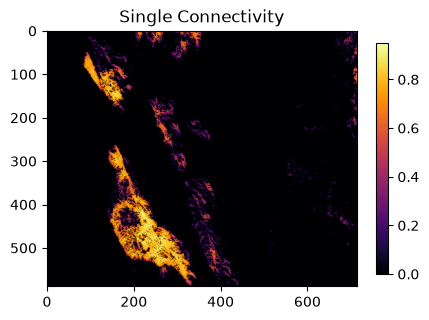

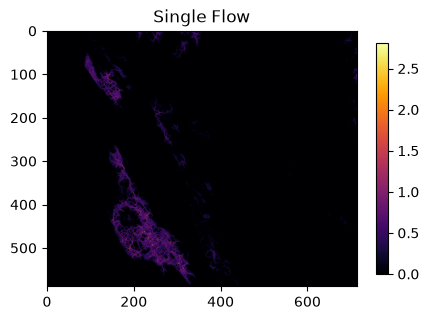

In [6]:
single_connectivity = GeoTiff.from_file(SINGLE_CONNECTIVITY_PATH)
t = single_connectivity.get_all_as_tile(b=0)
t.draw_tile(title="Single Connectivity")
single_flow = GeoTiff.from_file(SINGLE_FLOW_PATH)
t = single_flow.get_all_as_tile(b=0)
t.draw_tile(title="Single Flow")

In [7]:
ecoscape_connectivity.compute_connectivity(
    habitat_fn=HABITAT_PATH,
    landcover_fn=LANDCOVER_PATH,
    permeability_dict=permeability_dict,
    connectivity_fn=TILED_CONNECTIVITY_PATH,
    flow_fn=TILED_FLOW_PATH,
    border_size=50,
    tile_size=200,
    num_simulations=100,
    dispersal=ecoscape_connectivity.half_cauchy(10, 40),
)

(<scgt.scgt.GeoTiff at 0x120804750>, <scgt.scgt.GeoTiff at 0x120804450>)

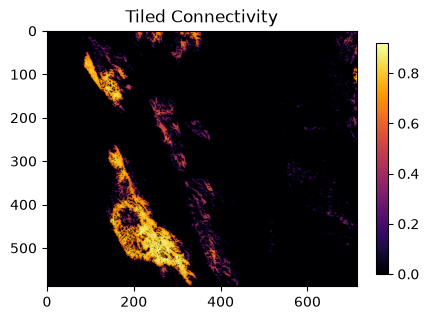

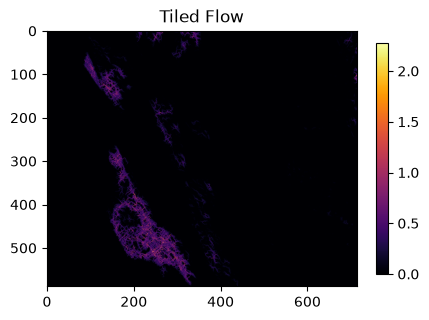

In [8]:
tiled_connectivity = GeoTiff.from_file(TILED_CONNECTIVITY_PATH)
tiled_connectivity.draw_geotiff(title="Tiled Connectivity")
tiled_flow = GeoTiff.from_file(TILED_FLOW_PATH)
tiled_flow.draw_geotiff(title="Tiled Flow")